# Figure S4

In [1]:
from riskhistory.format import rcParams
from riskhistory.config import results_pth
from riskhistory.data import load_ddm_posterior, DATASET_LABELS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
FULL_DDM_MODEL = "HDDM_Base_Lag1-full"

# (column, xtick label, color) -- one sideways histogram each
BIAS_PARAMS = [
    ("sp_bias",        "Starting point\nbias (∆z)", "#EBE8BD"),
    ("drift_bias",     "Fixed-drift\nbias (∆v)",    "#A8C199"),
    ("valuation_bias", "Valuation\nbias (∆λ)",      "#B9CCE4"),
]

### Helper functions

In [2]:
def loss_aversion_diff(gain, gain_cp, loss, loss_cp):
    """λ after accept − λ after reject, with λ = |v_loss / v_gain|
    (choice_prev1 coded +1 accept / −1 reject; same as figure3.ipynb's Val-CH)."""
    lambda_accept = np.abs((loss + loss_cp) / (gain + gain_cp))
    lambda_reject = np.abs((loss - loss_cp) / (gain - gain_cp))
    return lambda_accept - lambda_reject


def load_choicehistory_draws(model_id, dataset):
    """Pooled group-level posterior draws (4 chains flattened) of the three
    choice-history biases; the valuation bias is computed draw by draw."""
    posterior = load_ddm_posterior(model_id, dataset)
    draws = {name: posterior[name].flatten() for name in [
        "z_choice_prev1", "v_choice_prev1",
        "v_gain_centered", "v_gain_centered:choice_prev1",
        "v_loss_centered", "v_loss_centered:choice_prev1",
    ]}
    return pd.DataFrame({
        "sp_bias":        2 * draws["z_choice_prev1"],
        "drift_bias":     2 * draws["v_choice_prev1"],
        "valuation_bias": loss_aversion_diff(
            draws["v_gain_centered"], draws["v_gain_centered:choice_prev1"],
            draws["v_loss_centered"], draws["v_loss_centered:choice_prev1"],
        ),
    })


def plot_sample_hists(ax, draws, params, bins=40, max_width=0.7):
    """Sideways histograms (bins on the y-axis), one x position per parameter,
    with the mean (horizontal line) and 95% interval (vertical line left of each
    histogram) -- same style as figure5.ipynb's plot_param_hists.
    params: list of (column, xticklabel, color)."""
    for x, (col, _, color) in enumerate(params):
        samples = draws[col].values
        mean = samples.mean()
        lo, hi = np.percentile(samples, [2.5, 97.5])
        counts, edges = np.histogram(samples, bins=bins)
        left = x - max_width / 2
        right_edges = left + max_width * counts / counts.max()
        ax.stairs(right_edges, edges, baseline=left, orientation="horizontal",
                  fill=True, color=color, zorder=3)
        ax.stairs(right_edges, edges, baseline=left, orientation="horizontal",
                  color="black", linewidth=1.5, zorder=3)
        ax.plot([left, left + max_width], [mean, mean], color="black",
                linewidth=2.5, zorder=4)
        ax.plot([left - 0.06, left - 0.06], [lo, hi], color="black",
                linewidth=2.5, solid_capstyle="butt", zorder=4)

    ax.axhline(0, color="black", linestyle="--", linewidth=1.5, zorder=2)
    ax.set_xticks(range(len(params)))
    ax.set_xticklabels([label for _, label, _ in params], ha="center")
    ax.set_xlim(-0.6, len(params) - 0.4)
    ax.spines[["top", "right"]].set_visible(False)

### Figure: choice-history biases in the full DDM
Pooled group-level posterior draws (4 chains) of `HDDM_Base_Lag1-full`, one column per dataset, as sideways histograms (black line = mean, vertical line = 95% posterior interval). Starting-point and fixed-drift biases are 2 x the ±1-coded `choice_prev1` effect (accept − reject); the valuation bias is λ after accept − λ after reject, with λ = |v_loss / v_gain|, computed draw by draw.

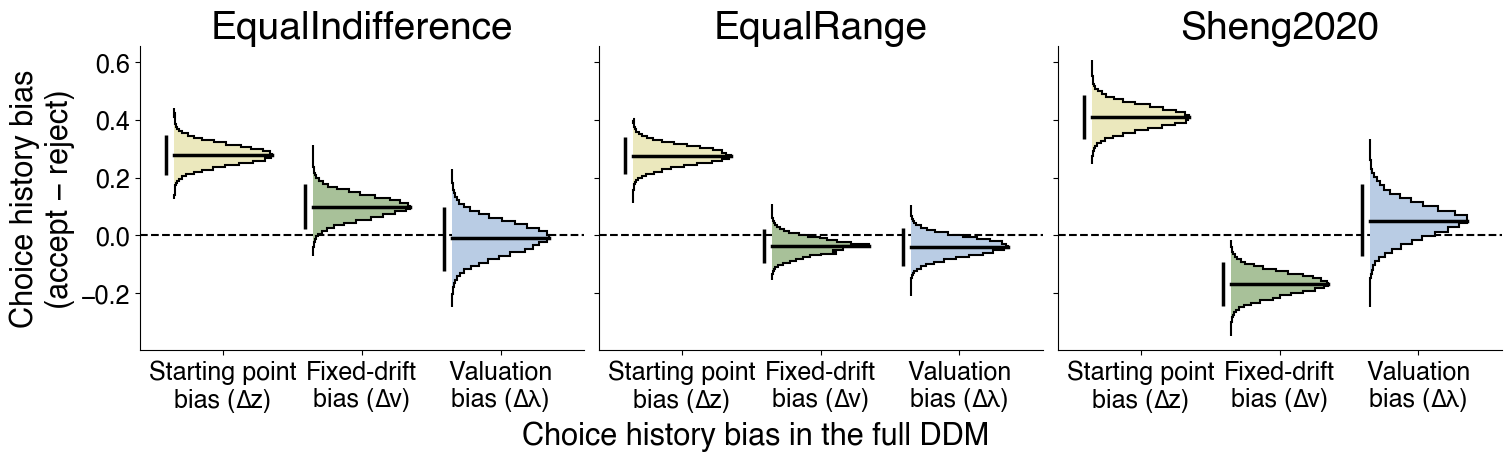

In [3]:
choicehistory_draws = {ds: load_choicehistory_draws(FULL_DDM_MODEL, ds) for ds in DATASETS}

fig, axes = plt.subplots(nrows=1, ncols=len(DATASETS), figsize=(15, 4.5),
                         sharey=True, layout="constrained")

for col, ds in enumerate(DATASETS):
    ax = axes[col]
    plot_sample_hists(ax, choicehistory_draws[ds], BIAS_PARAMS)
    ax.set_title(DATASET_LABELS.get(ds, ds))

axes[0].set_ylabel("Choice history bias\n(accept − reject)")
fig.supxlabel("Choice history bias in the full DDM", fontsize=plt.rcParams["axes.labelsize"])

fig.savefig("saved/figureS4_fullddm_hists.svg", dpi=300, bbox_inches="tight")
plt.show()

### Table: full DDM choice-history biases
Group-level posterior mean [95% posterior interval] per dataset, written to `results/ddm_full_choicehistory_posterior_tables.tex`.

In [4]:
TABLE_DATASET_NAMES = {
    "equalIndifference": "EqualIndifference",
    "equalRange": "EqualRange",
    "sheng2020": "Sheng2020",
}
TABLE_PARAM_LABELS = {
    "sp_bias":        "Starting-point bias ($2 \\times z_{\\mathrm{choice\\_prev1}}$)",
    "drift_bias":     "Drift bias ($2 \\times v_{\\mathrm{choice\\_prev1}}$)",
    "valuation_bias": "Valuation bias ($\\lambda_{A} - \\lambda_{R}$)",
}

rows = []
for param, _, _ in BIAS_PARAMS:
    for ds in DATASETS:
        samples = choicehistory_draws[ds][param]
        lo, hi = np.percentile(samples, [2.5, 97.5])
        rows.append({"parameter": param, "dataset": ds,
                     "mean": samples.mean(), "ci_lower": lo, "ci_upper": hi})
posterior_summary = pd.DataFrame(rows)
print(posterior_summary.round(3).to_string(index=False))


def format_posterior_cell(row):
    """Mean [95% posterior interval]."""
    return f"{row['mean']:.3f} [{row['ci_lower']:.3f}, {row['ci_upper']:.3f}]"


def write_posterior_table(f, title, caption, summary):
    f.write(f"\\subsection*{{{title}}}\n\n")
    f.write("\\begin{table}[h!]\n")
    f.write("\\centering\n")
    f.write("\\begin{tabular}{l" + "c" * len(DATASETS) + "}\n")
    f.write("\\hline\n")
    header = ["Parameter"] + [TABLE_DATASET_NAMES[ds] for ds in DATASETS]
    f.write(" & ".join(header) + " \\\\\n")
    f.write("\\hline\n")
    for param, _, _ in BIAS_PARAMS:
        cells = [TABLE_PARAM_LABELS[param]]
        for ds in DATASETS:
            row = summary[(summary["parameter"] == param) & (summary["dataset"] == ds)].iloc[0]
            cells.append(format_posterior_cell(row))
        f.write(" & ".join(cells) + " \\\\\n")
    f.write("\\hline\n")
    f.write("\\end{tabular}\n")
    f.write(f"\\caption{{{caption}}}\n")
    f.write("\\end{table}\n\n\n")
    f.write("\\newpage\n")


title = "Choice-history biases in the full DDM"
caption = (
    "Group-level posterior mean [95\\% posterior interval] "
    "(2.5th--97.5th percentiles of the pooled samples) of the choice-history biases "
    "in the full DDM. Starting-point and drift biases are the accept $-$ reject "
    "difference ($2\\times$ the $\\pm1$-coded effect); the valuation bias is the loss "
    "aversion $\\lambda = |v_{\\mathrm{loss}} / v_{\\mathrm{gain}}|$ after accept $-$ after reject."
)

output_path = results_pth / "ddm_full_choicehistory_posterior_tables.tex"
with open(output_path, "w") as f:
    write_posterior_table(f, title, caption, posterior_summary)

print()
print(output_path.read_text())

     parameter           dataset   mean  ci_lower  ci_upper
       sp_bias equalIndifference  0.279     0.210     0.348
       sp_bias        equalRange  0.276     0.211     0.340
       sp_bias         sheng2020  0.409     0.334     0.485
    drift_bias equalIndifference  0.099     0.021     0.176
    drift_bias        equalRange -0.037    -0.095     0.021
    drift_bias         sheng2020 -0.168    -0.244    -0.093
valuation_bias equalIndifference -0.010    -0.122     0.099
valuation_bias        equalRange -0.039    -0.106     0.025
valuation_bias         sheng2020  0.050    -0.072     0.177

\subsection*{Choice-history biases in the full DDM}

\begin{table}[h!]
\centering
\begin{tabular}{lccc}
\hline
Parameter & EqualIndifference & EqualRange & Sheng2020 \\
\hline
Starting-point bias ($2 \times z_{\mathrm{choice\_prev1}}$) & 0.279 [0.210, 0.348] & 0.276 [0.211, 0.340] & 0.409 [0.334, 0.485] \\
Drift bias ($2 \times v_{\mathrm{choice\_prev1}}$) & 0.099 [0.021, 0.176] & -0.037 [-0.095,